=== RUNNING PROPERLY ISOLATED ONE-VS-REST EVALUATION ON TRAINING SET ===
Evaluating binary classifier for class: Normal...
Evaluating binary classifier for class: Sag...
Evaluating binary classifier for class: Swell...
Evaluating binary classifier for class: Interruption...
Evaluating binary classifier for class: Harmonics...
Evaluating binary classifier for class: Sag_harmonics...
Evaluating binary classifier for class: Swell_harmonics...
Evaluating binary classifier for class: Transient...
Evaluating binary classifier for class: Flicker...


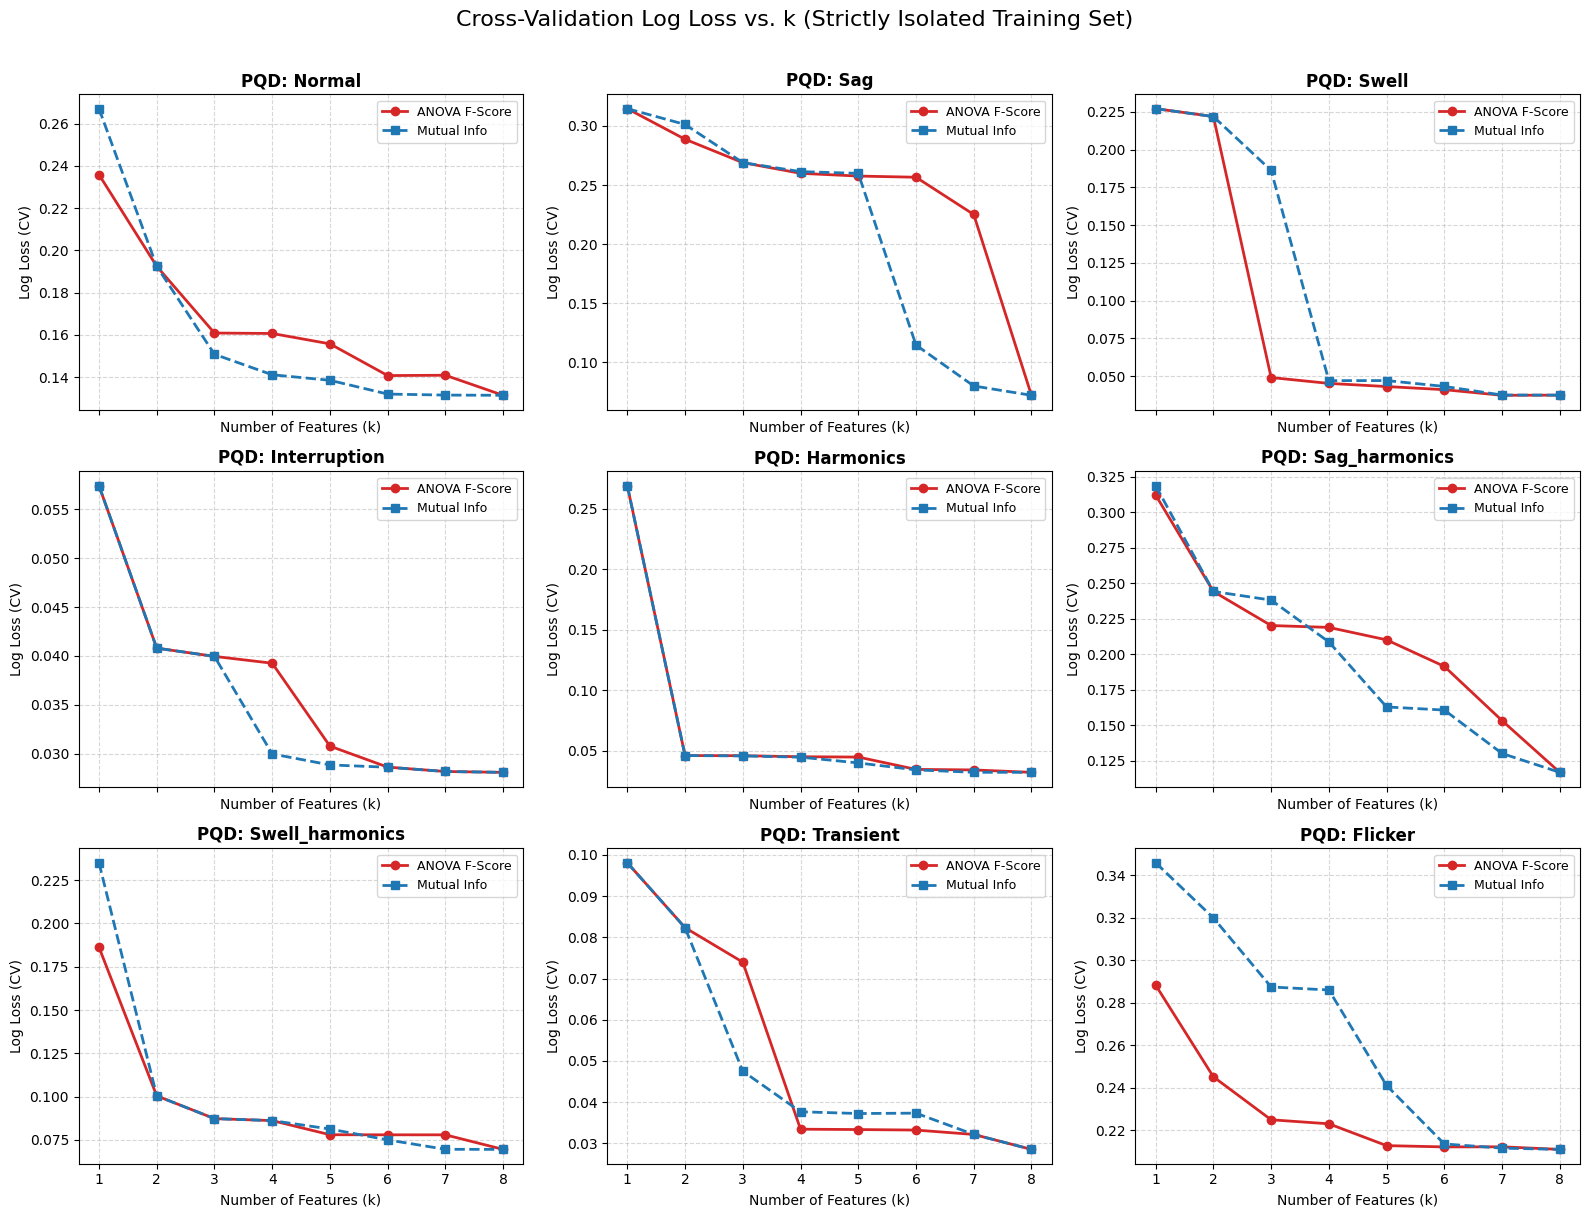

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from import_folder import PQD_INDICES, import_all_noiselevel_data

# -----------------------------------------------------------------------------
# 1. Load Multi-Noise Dataset & Create Strictly Isolated Train/Test Split
# -----------------------------------------------------------------------------
folders = ["SNR_noiseless", "SNR_50dB", "SNR_40dB", "SNR_30dB", "SNR_20dB"]
all_data = import_all_noiselevel_data(folders, add_noise_column=False)

X = all_data.drop(columns=["label"])
y = all_data["label"]

# STEP 1: Strict Holdout Split BEFORE ANY SELECTION OR TRAINING (80% Train, 20% Test)
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

CLASS_NAMES = {v: k for k, v in PQD_INDICES.items()}
unique_classes = sorted(y.unique())
max_k = X.shape[1]

# -----------------------------------------------------------------------------
# 2. Per-PQD Evaluation Using CV STRICTLY ON X_train_full
# -----------------------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pqd_results = {}

print("=== RUNNING PROPERLY ISOLATED ONE-VS-REST EVALUATION ON TRAINING SET ===")

for class_idx in unique_classes:
    class_name = CLASS_NAMES[class_idx]
    print(f"Evaluating binary classifier for class: {class_name}...")

    # Create binary target strictly on training split
    y_train_binary = (y_train_full == class_idx).astype(int)

    f_loss_means, mi_loss_means = [], []

    for k in range(1, max_k + 1):
        f_fold_losses, mi_fold_losses = [], []

        # Inner 5-Fold Cross-Validation on training data ONLY
        for train_idx, val_idx in cv.split(X_train_full, y_train_binary):
            # Split training set further into fold-train and fold-validation
            X_tr, X_val = X_train_full.iloc[train_idx], X_train_full.iloc[val_idx]
            y_tr, y_val = y_train_binary.iloc[train_idx], y_train_binary.iloc[val_idx]

            # Pipelines ensure fit_transform happens strictly on X_tr
            pipe_f = Pipeline(
                [
                    ("scaler", StandardScaler()),
                    ("select_k", SelectKBest(score_func=f_classif, k=k)),
                    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
                ]
            )

            pipe_mi = Pipeline(
                [
                    ("scaler", StandardScaler()),
                    ("select_k", SelectKBest(score_func=mutual_info_classif, k=k)),
                    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
                ]
            )

            # Fit and evaluate ANOVA
            pipe_f.fit(X_tr, y_tr)
            probs_f = pipe_f.predict_proba(X_val)
            f_fold_losses.append(log_loss(y_val, probs_f))

            # Fit and evaluate Mutual Information
            pipe_mi.fit(X_tr, y_tr)
            probs_mi = pipe_mi.predict_proba(X_val)
            mi_fold_losses.append(log_loss(y_val, probs_mi))

        # Store mean loss across CV folds
        f_loss_means.append(np.mean(f_fold_losses))
        mi_loss_means.append(np.mean(mi_fold_losses))

    pqd_results[class_name] = {
        "k_values": list(range(1, max_k + 1)),
        "f_score_loss": f_loss_means,
        "mi_score_loss": mi_loss_means,
    }

# -----------------------------------------------------------------------------
# 3. Plot 9-Panel Performance Grid
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharex=True)
axes = axes.flatten()

for idx, class_idx in enumerate(unique_classes):
    class_name = CLASS_NAMES[class_idx]
    res = pqd_results[class_name]
    ax = axes[idx]

    ax.plot(
        res["k_values"],
        res["f_score_loss"],
        marker="o",
        color="tab:red",
        linewidth=2,
        label="ANOVA F-Score",
    )
    ax.plot(
        res["k_values"],
        res["mi_score_loss"],
        marker="s",
        color="tab:blue",
        linewidth=2,
        linestyle="--",
        label="Mutual Info",
    )

    ax.set_title(f"PQD: {class_name}", fontsize=12, fontweight="bold")
    ax.set_ylabel("Log Loss (CV)", fontsize=10)
    ax.set_xlabel("Number of Features (k)", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=9)

plt.suptitle(
    "Cross-Validation Log Loss vs. k (Strictly Isolated Training Set)",
    fontsize=16,
    y=1.01,
)
plt.tight_layout()
plt.show()

In [23]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# -----------------------------------------------------------------------------
# 1. Class-Specific Optimal Configuration Dictionary
# -----------------------------------------------------------------------------
# Fill/adjust 'k' and 'scorer' ('anova' or 'mi') based on visual inspection
# of your 9-panel Log Loss vs. k cross-validation graphs.
OPTIMAL_CONFIG_PER_PQD = {
    "Normal": {"k": 6, "scorer": "mi"},
    "Sag": {"k": 7, "scorer": "mi"},
    "Swell": {"k": 5, "scorer": "anova"},
    "Interruption": {"k": 5, "scorer": "mi"},
    "Harmonics": {"k": 2, "scorer": "anova"},
    "Sag_harmonics": {"k": 7, "scorer": "mi"},
    "Swell_harmonics": {"k": 5, "scorer": "anova"},
    "Transient": {"k": 4, "scorer": "anova"},
    "Flicker": {"k": 5, "scorer": "anova"},
}

# -----------------------------------------------------------------------------
# 2. Extract Features & Evaluate Class-Tailored Binary Pipelines
# -----------------------------------------------------------------------------
task1_summary = []

print("=== TASK 1 FINAL EVALUATION: CLASS-SPECIFIC FEATURE SUBSETS ===\n")

for class_idx in unique_classes:
    class_name = CLASS_NAMES[class_idx]
    config = OPTIMAL_CONFIG_PER_PQD[class_name]

    k_opt = config["k"]
    scorer_type = config["scorer"]
    score_func = f_classif if scorer_type == "anova" else mutual_info_classif

    # Prepare binary targets strictly on isolated splits
    y_train_binary = (y_train_full == class_idx).astype(int)
    y_test_binary = (y_test_full == class_idx).astype(int)

    # Build and fit optimal binary pipeline on X_train
    class_pipeline = Pipeline(
        [
            ("scaler", StandardScaler()),
            ("select_k", SelectKBest(score_func=score_func, k=k_opt)),
            (
                "classifier",
                LogisticRegression(max_iter=10000, random_state=42),
            ),
        ]
    )

    class_pipeline.fit(X_train_full, y_train_binary)

    # Extract selected feature names
    selected_mask = class_pipeline.named_steps["select_k"].get_support()
    selected_features = list(X_train_full.columns[selected_mask])

    # Evaluate probabilities on unseen Holdout Test Set (X_test)
    y_probs_test = class_pipeline.predict_proba(X_test_full)
    test_loss = log_loss(y_test_binary, y_probs_test)
    train_f1 = f1_score(y_train_binary, class_pipeline.predict(X_train_full))
    test_f1 = f1_score(y_test_binary, class_pipeline.predict(X_test_full))

    # Collect results
    task1_summary.append(
        {
            "PQD Class": class_name,
            "Optimal k": k_opt,
            "Best Scorer": scorer_type.upper(),
            "Holdout Test Log Loss": round(test_loss, 4),
            "Training F1 Score": round(train_f1, 4),
            "Selected Features": ", ".join(selected_features),
        }
    )

# -----------------------------------------------------------------------------
# 3. Display Task 1 Summary DataFrame
# -----------------------------------------------------------------------------
summary_df = pd.DataFrame(task1_summary)
pd.set_option("display.max_colwidth", None)

print("=== TASK 1 FINAL FEATURE SELECTION TABLE ===")
print(summary_df.to_string(index=False))

=== TASK 1 FINAL EVALUATION: CLASS-SPECIFIC FEATURE SUBSETS ===

=== TASK 1 FINAL FEATURE SELECTION TABLE ===
      PQD Class  Optimal k Best Scorer  Holdout Test Log Loss  Training F1 Score                                                                                       Selected Features
         Normal          6          MI                 0.1245             0.7844                   F1:avg_abs_ST_3rd, F2:std_TmA, F3:max_TmA, F4:min_TmA, F6:std_FmA_3_7, F7:std_FmA_gt3
            Sag          7          MI                 0.0675             0.8735 F1:avg_abs_ST_3rd, F2:std_TmA, F3:max_TmA, F4:min_TmA, F6:std_FmA_3_7, F7:std_FmA_gt3, F8:near_zero_cnt
          Swell          5       ANOVA                 0.0394             0.9413                             F1:avg_abs_ST_3rd, F3:max_TmA, F4:min_TmA, F6:std_FmA_3_7, F8:near_zero_cnt
   Interruption          5          MI                 0.0252             0.9733                             F1:avg_abs_ST_3rd, F2:std_TmA, F4:min_TmA